In [1]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np


plotly_template = pio.templates["plotly_white"]
plotly_template.layout['font']['family'] = 'Avenir Next'
plotly_template.layout['font']['color'] = 'black'
plotly_template.layout['font']['size'] = 15
plotly_template.layout['title']['font']['family'] = "Avenir Next"
plotly_template.layout['title']['font']['color'] = "black"
plotly_template.layout['title']['font']['size'] = 40
plotly_template.layout['legend']['font']['size'] = 10
color1 = "rgba(255,165,86,1.0)"
color1_fill = "rgba(255,165,86,0.2)"
color2 = "rgba(98,159,202,1.0)"
color2_fill = "rgba(98,159,202,0.2)"
color3 = "rgba(226,103,104,1.0)"
color3_fill = "rgba(226,103,104,0.2)"


In [2]:
# Sample dataset ~ D
N = 100
X = 6*np.random.rand(N, 1) - 3
y = 2 + X + 0.5 * X**2 + np.random.randn(N, 1)

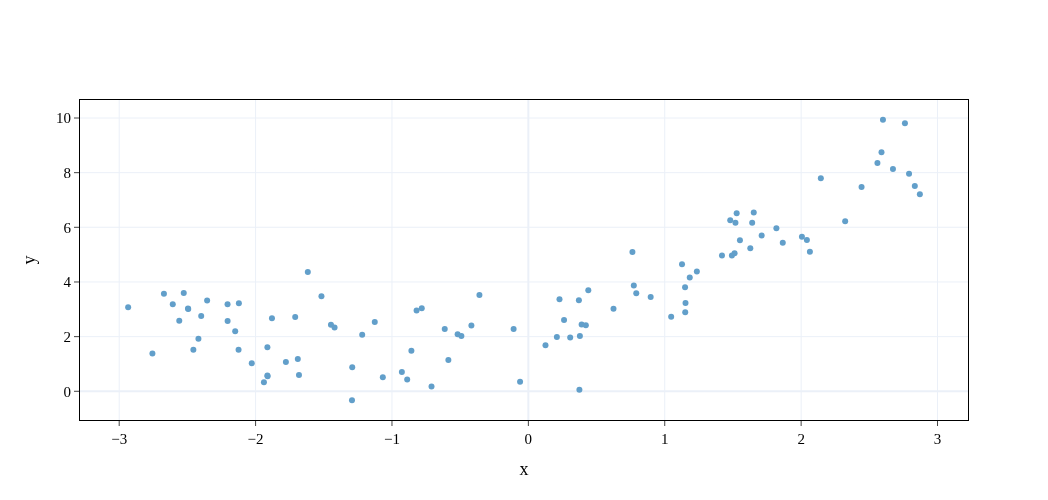

In [3]:
# Plotting stuff

x_space = np.linspace(-3,3,1000)
fig = go.Figure(data=go.Scatter(
    y = y.reshape(-1),
    x=X.reshape(-1),
    mode='markers',
    marker_color=color2,showlegend=False
))
fig.update_layout(template=plotly_template, width=800, height=500)
fig.update_layout(
    xaxis=dict(mirror=True,
    ticks='outside',
    showline=True),
    yaxis=dict(mirror=True,
    ticks='outside',
    showline=True),
    autosize=True)
fig.update_xaxes(showline=True, linewidth=1., linecolor='black',title='x')
fig.update_yaxes(showline=True, linewidth=1., linecolor='black',title= 'y')
fig.show()

In [4]:
# Apply basis functions, map from x -> phi(x)
from sklearn.preprocessing import PolynomialFeatures
poly_features = PolynomialFeatures(degree=2, include_bias=True)
Phi = poly_features.fit_transform(X)
print("Original: ", X[0])
print("Polynomial: ", Phi[0])

Original:  [1.12656759]
Polynomial:  [1.         1.12656759 1.26915455]


In [5]:
# Compute w^* = (Phi^T Phi)^-1 Phi^T y
w_star = np.linalg.inv(Phi.T@Phi)@(Phi.T @ y)

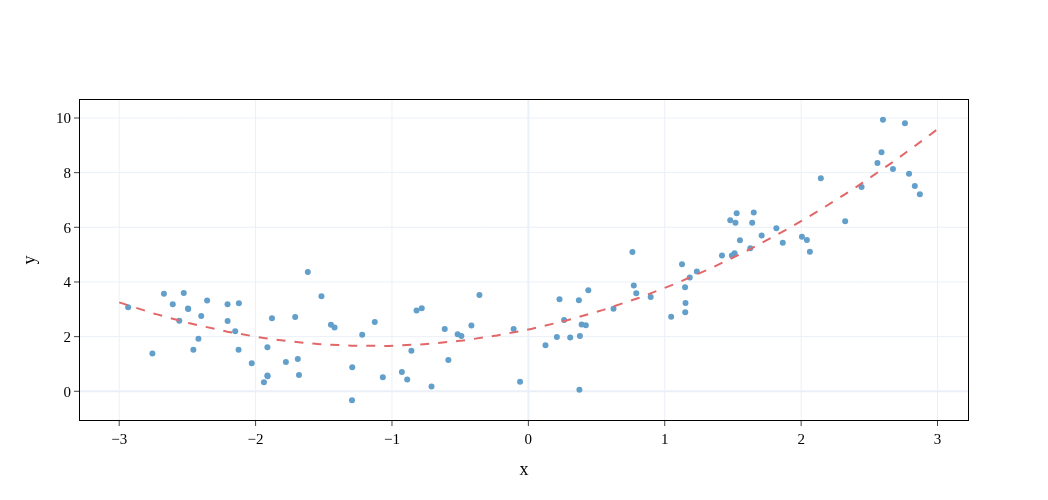

In [6]:
# Plotting stuff
x_space = np.linspace(-3,3,1000)
fig = go.Figure(data=go.Scatter(
    y = y.reshape(-1),
    x=X.reshape(-1),
    mode='markers',
    marker_color=color2,showlegend=False
))
fig.add_trace(go.Scatter(
    y =  (poly_features.fit_transform(x_space.reshape(-1,1))@w_star).reshape(-1),
    x=x_space,
    mode='lines',
    line_dash ='dash',
    marker_color=color3,
    showlegend=False))
fig.update_layout(template=plotly_template, width=800, height=500)
fig.update_layout(
    xaxis=dict(mirror=True,
    ticks='outside',
    showline=True),
    yaxis=dict(mirror=True,
    ticks='outside',
    showline=True),
    autosize=True)
fig.update_xaxes(showline=True, linewidth=1., linecolor='black',title='x')
fig.update_yaxes(showline=True, linewidth=1., linecolor='black',title= 'y')
fig.show()

In [7]:
def plot(degree):
    poly_features = PolynomialFeatures(degree=degree, include_bias=True)
    X_poly = poly_features.fit_transform(X) 
    w_hat = np.linalg.inv(X_poly.T@X_poly)@(X_poly.T @ y)
    x_space = np.linspace(-3,3,1000)

    fig = go.Figure(data=go.Scatter(
        y = y.reshape(-1),
        x=X.reshape(-1),
        mode='markers',
        marker_color=color2,showlegend=False
    ))
    fig.add_trace(go.Scatter(
        y =  (poly_features.fit_transform(x_space.reshape(-1,1))@w_hat).reshape(-1),
        x=x_space,
        mode='lines',
        line_dash ='dash',
        marker_color=color3,
        showlegend=False))
    fig.update_layout(template=plotly_template, width=800, height=500)
    fig.update_layout(
        xaxis=dict(mirror=True,
        ticks='outside',
        showline=True),
        yaxis=dict(mirror=True,
        ticks='outside',
        showline=True),
        autosize=True)
    fig.update_xaxes(showline=True, linewidth=1., linecolor='black',title='x')
    fig.update_yaxes(showline=True, linewidth=1., linecolor='black',title= 'y')
    fig.show()


In [8]:
import ipywidgets as widgets
widgets.interact(plot, degree=[0,1,2,15])

interactive(children=(Dropdown(description='degree', options=(0, 1, 2, 15), value=0), Output()), _dom_classes=…

<function __main__.plot(degree)>

In [9]:
# Sample dataset ~ D
N = 100
X = 6*np.random.rand(N, 1) - 3
y = 2*np.sin(X.reshape(-1)) + np.cos(X.reshape(-1))+ np.random.normal(size=N,scale=0.5)

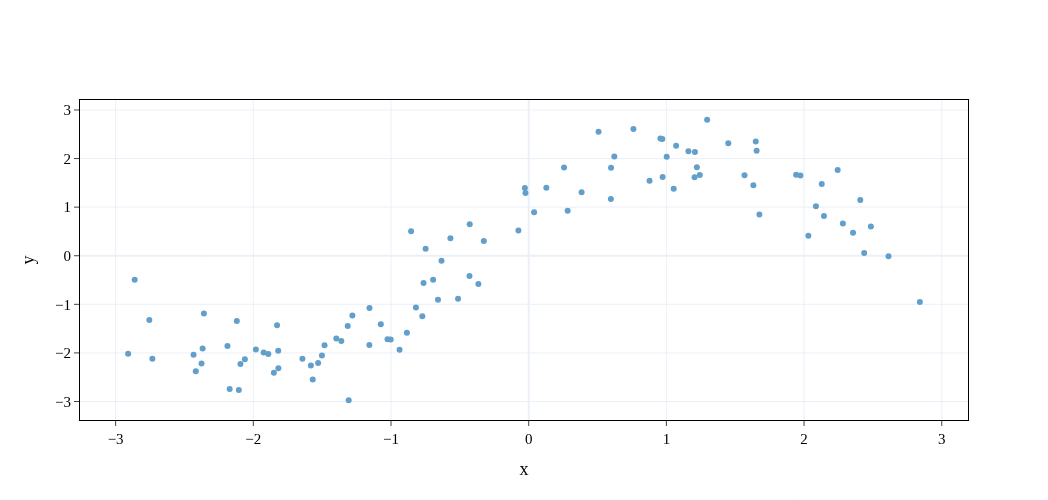

In [10]:
# Plotting stuff

x_space = np.linspace(-3,3,1000)
fig = go.Figure(data=go.Scatter(
    y = y.reshape(-1),
    x=X.reshape(-1),
    mode='markers',
    marker_color=color2,showlegend=False
))
fig.update_layout(template=plotly_template, width=800, height=500)
fig.update_layout(
    xaxis=dict(mirror=True,
    ticks='outside',
    showline=True),
    yaxis=dict(mirror=True,
    ticks='outside',
    showline=True),
    autosize=True)
fig.update_xaxes(showline=True, linewidth=1., linecolor='black',title='x')
fig.update_yaxes(showline=True, linewidth=1., linecolor='black',title= 'y')
fig.show()

In [11]:
# Apply basis functions, map from x -> phi(x)
sin_phi = np.sin(X)
cos_phi = np.cos(X)
Phi = np.hstack((sin_phi, cos_phi))

In [12]:
# Compute w^* = (Phi^T Phi)^-1 Phi^T y
w_star = np.linalg.inv(Phi.T@Phi)@(Phi.T @ y)

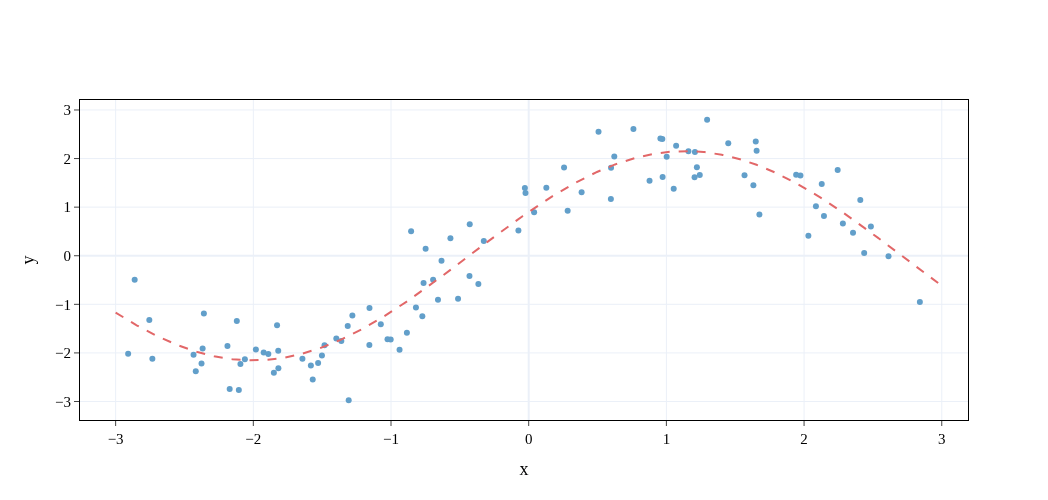

In [13]:
# Plotting stuff
x_space = np.linspace(-3,3,1000)
fig = go.Figure(data=go.Scatter(
    y = y.reshape(-1),
    x=X.reshape(-1),
    mode='markers',
    marker_color=color2,showlegend=False
))
fig.add_trace(go.Scatter(
    y =  (np.hstack((np.sin(x_space.reshape(-1,1)), np.cos(x_space.reshape(-1,1))))@w_star).reshape(-1),
    x=x_space,
    mode='lines',
    line_dash ='dash',
    marker_color=color3,
    showlegend=False))
fig.update_layout(template=plotly_template, width=800, height=500)
fig.update_layout(
    xaxis=dict(mirror=True,
    ticks='outside',
    showline=True),
    yaxis=dict(mirror=True,
    ticks='outside',
    showline=True),
    autosize=True)
fig.update_xaxes(showline=True, linewidth=1., linecolor='black',title='x')
fig.update_yaxes(showline=True, linewidth=1., linecolor='black',title= 'y')
fig.show()
